In [1]:
import cma, botorch, torch, gpytorch
print(cma.__version__, botorch.__version__, torch.__version__)

C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


4.5.0 0.18.1 2.14.1+cpu


In [3]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\aksha\anaconda3\envs\bo_cma\python.exe
Python version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]


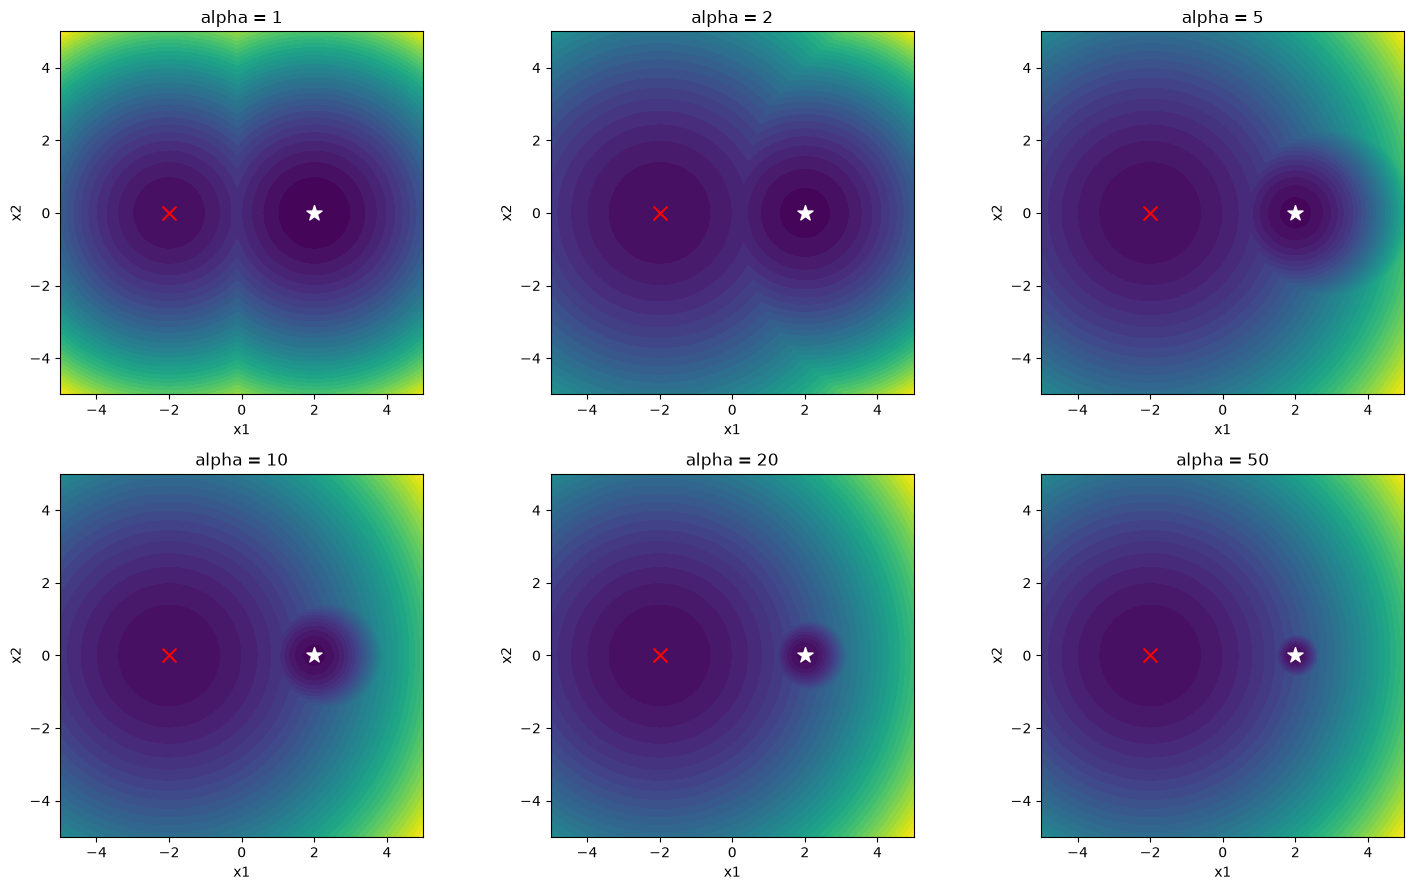

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from objective import two_basin

ALPHAS = [1, 2, 5, 10, 20, 50]
DISTANCE = 4
DELTA = 1

x1 = np.linspace(-5, 5, 300)
x2 = np.linspace(-5, 5, 300)

X1, X2 = np.meshgrid(x1, x2)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, alpha in zip(axes.flat, ALPHAS):

    Z = np.array([
        two_basin(
            [x, y],
            alpha=alpha,
            distance=DISTANCE,
            delta=DELTA
        )
        for x, y in zip(X1.ravel(), X2.ravel())
    ]).reshape(X1.shape)

    ax.contourf(X1, X2, Z, levels=40, cmap="viridis")

    ax.scatter(-2, 0, color="red", marker="x", s=100,
               label="Local minimum")
    ax.scatter(2, 0, color="white", marker="*", s=130,
               label="Global minimum")

    ax.set_title(f"alpha = {alpha}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import cma

def run_cmaes(alpha, distance=4, delta=1, budget=300, seed=0):

    rng = np.random.default_rng(seed)

    x0 = rng.uniform(-5, 5, size=2)

    es = cma.CMAEvolutionStrategy(
        x0,
        2.0,
        {
            "bounds": [[-5, -5], [5, 5]],
            "seed": seed + 1,
            "verbose": -9,
            "maxfevals": budget,
        }
    )

    X_history = []
    y_history = []

    while not es.stop():

        # Stop if insufficient budget for another generation
        if len(y_history) + es.popsize > budget:
            break

        solutions = es.ask()

        values = [
            two_basin(
                x,
                alpha=alpha,
                distance=distance,
                delta=delta
            )
            for x in solutions
        ]

        es.tell(solutions, values)

        X_history.extend(solutions)
        y_history.extend(values)

    X_history = np.asarray(X_history)
    y_history = np.asarray(y_history)

    # Use remaining evaluations without another CMA-ES update
    remaining = budget - len(y_history)

    if remaining > 0:
        extra_solutions = es.ask(number=remaining)

        extra_values = [
            two_basin(
                x,
                alpha=alpha,
                distance=distance,
                delta=delta
            )
            for x in extra_solutions
        ]

        X_history = np.vstack([X_history, extra_solutions])
        y_history = np.concatenate([y_history, extra_values])

    best_idx = np.argmin(y_history)

    return {
        "best_x": X_history[best_idx],
        "best_f": y_history[best_idx],
        "X_history": X_history,
        "y_history": y_history,
        "best_history": np.minimum.accumulate(y_history),
        "n_evals": len(y_history),
        "stop_reason": es.stop(),
        "population_size": es.popsize,
        "generations": es.countiter
    }

In [6]:
result = run_cmaes(
    alpha=10,
    distance=4,
    delta=1,
    budget=300,
    seed=0
)

print("Best solution:", result["best_x"])
print("Best objective value:", result["best_f"])
print("Evaluations used:", result["n_evals"])
print("Simple regret:", result["best_f"] + 1)

Best solution: [1.86560652 0.28292015]
Best objective value: -0.018945808152253885
Evaluations used: 300
Simple regret: 0.9810541918477461


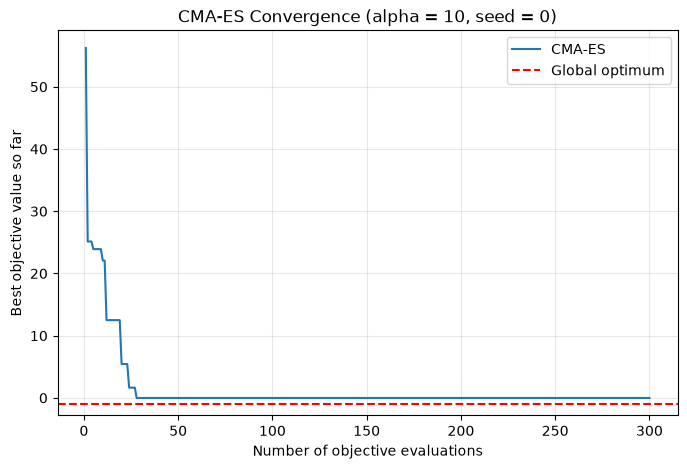

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(1, result["n_evals"] + 1),
    result["best_history"],
    label="CMA-ES"
)

plt.axhline(
    y=-1,
    color="red",
    linestyle="--",
    label="Global optimum"
)

plt.xlabel("Number of objective evaluations")
plt.ylabel("Best objective value so far")
plt.title("CMA-ES Convergence (alpha = 10, seed = 0)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
def in_global_basin(x, alpha, distance=4, delta=1):
    x = np.asarray(x)

    a = np.array([-2.0, 0.0])
    b = a + np.array([distance, 0.0])

    local = np.sum((x - a)**2)
    global_value = alpha * np.sum((x - b)**2) - delta

    return global_value < local

In [9]:
discovered = any(
    in_global_basin(x, alpha=10)
    for x in result["X_history"]
)

print("Global basin discovered:", discovered)
print("Final simple regret:", result["best_f"] + 1)

Global basin discovered: True
Final simple regret: 0.9810541918477461


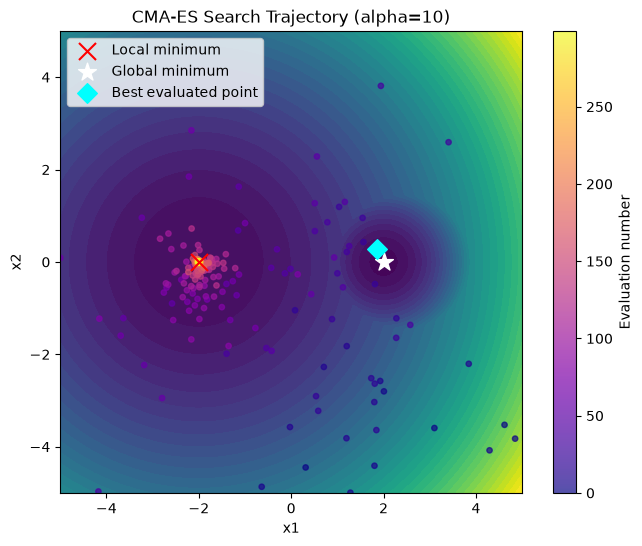

In [10]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 10

x1 = np.linspace(-5, 5, 300)
x2 = np.linspace(-5, 5, 300)
X1, X2 = np.meshgrid(x1, x2)

Z = np.array([
    two_basin([x, y], alpha=alpha)
    for x, y in zip(X1.ravel(), X2.ravel())
]).reshape(X1.shape)

fig, ax = plt.subplots(figsize=(8, 6))

ax.contourf(X1, X2, Z, levels=40, cmap="viridis")

points = result["X_history"]

scatter = ax.scatter(
    points[:, 0],
    points[:, 1],
    c=np.arange(len(points)),
    cmap="plasma",
    s=15,
    alpha=0.7
)

ax.scatter(-2, 0, color="red", marker="x",
           s=150, label="Local minimum")

ax.scatter(2, 0, color="white", marker="*",
           s=180, label="Global minimum")

ax.scatter(
    result["best_x"][0],
    result["best_x"][1],
    color="cyan",
    marker="D",
    s=100,
    label="Best evaluated point"
)

plt.colorbar(scatter, ax=ax, label="Evaluation number")

ax.set_title("CMA-ES Search Trajectory (alpha=10)")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.set_aspect("equal")

plt.show()

In [11]:
result = run_cmaes(
    alpha=10,
    distance=4,
    delta=1,
    budget=300,
    seed=0
)

print("Population size:", result["population_size"])
print("Generations completed:", result["generations"])
print("Total evaluations:", result["n_evals"])
print("Best solution:", result["best_x"])
print("Best objective:", result["best_f"])
print("Simple regret:", result["best_f"] + 1)

Population size: 6
Generations completed: 50
Total evaluations: 300
Best solution: [1.86560652 0.28292015]
Best objective: -0.018945808152253885
Simple regret: 0.9810541918477461


In [12]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from objective import two_basin

from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition import LogExpectedImprovement
from botorch.optim import optimize_acqf

from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.models.transforms.input import Normalize

In [13]:
def run_bo(
    alpha,
    distance=4,
    delta=1,
    budget=300,
    seed=0,
    n_initial=10
):
    torch.manual_seed(seed)
    torch.set_default_dtype(torch.double)

    bounds = torch.tensor([
        [-5.0, -5.0],
        [5.0, 5.0]
    ], dtype=torch.double)

    # Initial Sobol design
    sobol = torch.quasirandom.SobolEngine(
        dimension=2,
        scramble=True,
        seed=seed
    )

    X = bounds[0] + (
        bounds[1] - bounds[0]
    ) * sobol.draw(n_initial).double()

    y = torch.tensor([
        two_basin(
            x.numpy(),
            alpha=alpha,
            distance=distance,
            delta=delta
        )
        for x in X
    ], dtype=torch.double).unsqueeze(-1)

    # Sequential BO
    while len(X) < budget:

        # Standardise objective values
        y_mean = y.mean()
        y_std = y.std().clamp_min(1e-8)

        y_scaled = (y - y_mean) / y_std

        # Fit Gaussian Process
        model = SingleTaskGP(
            train_X=X,
            train_Y=y_scaled,
            input_transform=Normalize(d=2, bounds=bounds)
            )

        mll = ExactMarginalLogLikelihood(
            model.likelihood,
            model
        )

        fit_gpytorch_mll(mll)

        # Expected improvement for minimisation
        acquisition = LogExpectedImprovement(
            model=model,
            best_f=y_scaled.min().item(),
            maximize=False
        )

        candidate, _ = optimize_acqf(
            acq_function=acquisition,
            bounds=bounds,
            q=1,
            num_restarts=5,
            raw_samples=64
        )

        x_next = candidate.detach()

        y_next = torch.tensor([[
            two_basin(
                x_next[0].numpy(),
                alpha=alpha,
                distance=distance,
                delta=delta
            )
        ]], dtype=torch.double)

        X = torch.cat([X, x_next], dim=0)
        y = torch.cat([y, y_next], dim=0)

    X_history = X.numpy()
    y_history = y.squeeze(-1).numpy()

    best_idx = np.argmin(y_history)

    return {
        "best_x": X_history[best_idx],
        "best_f": y_history[best_idx],
        "X_history": X_history,
        "y_history": y_history,
        "best_history": np.minimum.accumulate(y_history),
        "n_evals": len(y_history)
    }

In [14]:
bo_result = run_bo(
    alpha=10,
    distance=4,
    delta=1,
    budget=300,
    seed=0,
    n_initial=10
)

print("Best solution:", bo_result["best_x"])
print("Best objective:", bo_result["best_f"])
print("Evaluations:", bo_result["n_evals"])
print("Simple regret:", bo_result["best_f"] + 1)

Best solution: [-1.99833056  0.0113933 ]
Best objective: 0.00013259436144644408
Evaluations: 300
Simple regret: 1.0001325943614465


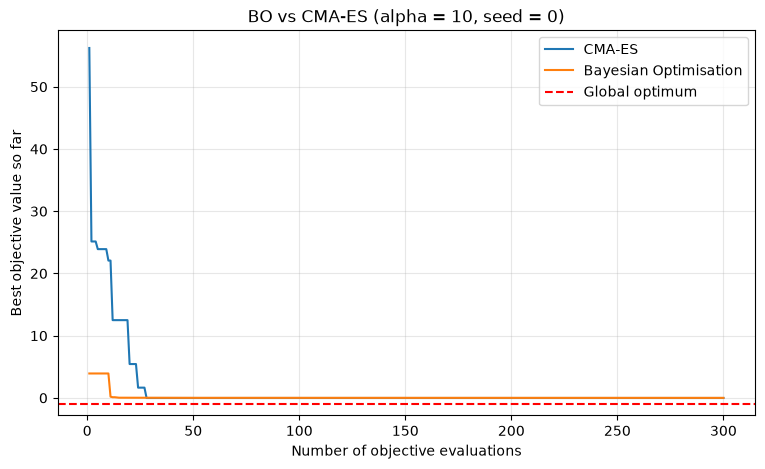

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, result["n_evals"] + 1),
    result["best_history"],
    label="CMA-ES"
)

plt.plot(
    np.arange(1, bo_result["n_evals"] + 1),
    bo_result["best_history"],
    label="Bayesian Optimisation"
)

plt.axhline(
    y=-1,
    color="red",
    linestyle="--",
    label="Global optimum"
)

plt.xlabel("Number of objective evaluations")
plt.ylabel("Best objective value so far")
plt.title("BO vs CMA-ES (alpha = 10, seed = 0)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:
def first_global_discovery(X_history, alpha, distance=4, delta=1):
    for i, x in enumerate(X_history):
        if in_global_basin(
            x,
            alpha=alpha,
            distance=distance,
            delta=delta
        ):
            return i + 1

    return None

In [17]:
for method, res in [
    ("CMA-ES", result),
    ("BO", bo_result)
]:
    first_hit = first_global_discovery(
        res["X_history"],
        alpha=10
    )

    print(f"\n{method}")
    print("First global discovery:", first_hit)
    print("Best objective:", res["best_f"])
    print("Simple regret:", res["best_f"] + 1)
    print("Evaluations:", res["n_evals"])



CMA-ES
First global discovery: 22
Best objective: -0.018945808152253885
Simple regret: 0.9810541918477461
Evaluations: 300

BO
First global discovery: None
Best objective: 0.00013259436144644408
Simple regret: 1.0001325943614465
Evaluations: 300


In [18]:
Z = np.array([
    two_basin([x, y], alpha=10, distance=4, delta=1)
    for x, y in zip(X1.ravel(), X2.ravel())
]).reshape(X1.shape)

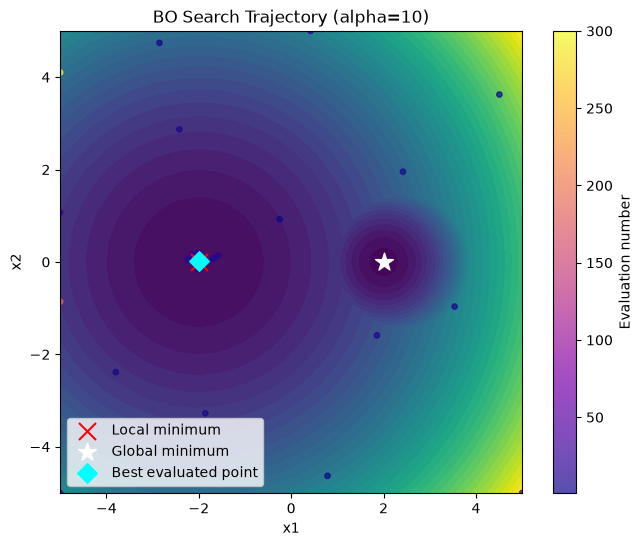

In [19]:
alpha = 10

fig, ax = plt.subplots(figsize=(8, 6))

ax.contourf(X1, X2, Z, levels=40, cmap="viridis")

points = bo_result["X_history"]

scatter = ax.scatter(
    points[:, 0],
    points[:, 1],
    c=np.arange(1, len(points) + 1),
    cmap="plasma",
    s=15,
    alpha=0.7
)

ax.scatter(-2, 0, color="red", marker="x",
           s=150, label="Local minimum")

ax.scatter(2, 0, color="white", marker="*",
           s=180, label="Global minimum")

ax.scatter(
    bo_result["best_x"][0],
    bo_result["best_x"][1],
    color="cyan",
    marker="D",
    s=100,
    label="Best evaluated point"
)

plt.colorbar(scatter, ax=ax, label="Evaluation number")

ax.set_title("BO Search Trajectory (alpha=10)")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.set_aspect("equal")

plt.show()

In [20]:
initial_points = bo_result["X_history"][:10]

initial_hits = [
    in_global_basin(x, alpha=10)
    for x in initial_points
]

print("Initial BO points in global basin:", sum(initial_hits))

all_hits = [
    in_global_basin(x, alpha=10)
    for x in bo_result["X_history"]
]

print("Total BO points in global basin:", sum(all_hits))

Initial BO points in global basin: 0
Total BO points in global basin: 0


In [21]:
from pathlib import Path

RESULTS_DIR = Path("results/experiment1")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [22]:
import pandas as pd
import time

ALPHAS_PILOT = [1, 10, 50]
SEEDS_PILOT = range(5)
BUDGET = 300

records = []

for alpha in ALPHAS_PILOT:
    for seed in SEEDS_PILOT:
        for method, runner in [
            ("CMA-ES", run_cmaes),
            ("BO", run_bo)
        ]:
            print(
                f"Running {method}, "
                f"alpha={alpha}, seed={seed}",
                flush=True
            )

            start = time.perf_counter()

            res = runner(
                alpha=alpha,
                distance=4,
                delta=1,
                budget=BUDGET,
                seed=seed
            )

            elapsed = time.perf_counter() - start

            first_hit = first_global_discovery(
                res["X_history"],
                alpha=alpha
            )

            regret = max(0.0, res["best_f"] + 1)

            records.append({
                "method": method,
                "alpha": alpha,
                "seed": seed,
                "best_f": res["best_f"],
                "simple_regret": regret,
                "discovered_global": first_hit is not None,
                "first_discovery_eval": first_hit,
                "optimization_success": regret <= 0.01,
                "n_evals": res["n_evals"],
                "runtime_seconds": elapsed
            })

            # Save after every completed run
            pd.DataFrame(records).to_csv(
                RESULTS_DIR / "pilot_results.csv",
                index=False
            )

print("Pilot completed!")

Running CMA-ES, alpha=1, seed=0
Running BO, alpha=1, seed=0
Running CMA-ES, alpha=1, seed=1
Running BO, alpha=1, seed=1
Running CMA-ES, alpha=1, seed=2
Running BO, alpha=1, seed=2


C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Running CMA-ES, alpha=1, seed=3
Running BO, alpha=1, seed=3
Running CMA-ES, alpha=1, seed=4
Running BO, alpha=1, seed=4
Running CMA-ES, alpha=10, seed=0
Running BO, alpha=10, seed=0
Running CMA-ES, alpha=10, seed=1
Running BO, alpha=10, seed=1
Running CMA-ES, alpha=10, seed=2
Running BO, alpha=10, seed=2
Running CMA-ES, alpha=10, seed=3
Running BO, alpha=10, seed=3
Running CMA-ES, alpha=10, seed=4
Running BO, alpha=10, seed=4
Running CMA-ES, alpha=50, seed=0
Running BO, alpha=50, seed=0
Running CMA-ES, alpha=50, seed=1
Running BO, alpha=50, seed=1
Running CMA-ES, alpha=50, seed=2
Running BO, alpha=50, seed=2
Running CMA-ES, alpha=50, seed=3
Running BO, alpha=50, seed=3
Running CMA-ES, alpha=50, seed=4
Running BO, alpha=50, seed=4


C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Pilot completed!


In [23]:
pilot_df = pd.read_csv(
    RESULTS_DIR / "pilot_results.csv"
)

summary = (
    pilot_df
    .groupby(["method", "alpha"])
    .agg(
        discovery_rate=("discovered_global", "mean"),
        success_rate=("optimization_success", "mean"),
        mean_regret=("simple_regret", "mean"),
        median_regret=("simple_regret", "median"),
        mean_runtime=("runtime_seconds", "mean")
    )
    .reset_index()
)

display(summary)

,method,alpha,discovery_rate,success_rate,mean_regret,median_regret,mean_runtime
0,BO,1,1.0,1.0,0.001499,4.469863e-04,247.673420
1,BO,10,0.4,0.0,1.000090,1.000133e+00,233.601798
2,BO,50,0.0,0.0,1.000099,1.000114e+00,213.273983
3,CMA-ES,1,1.0,0.8,0.200000,4.134541e-09,0.141846
4,CMA-ES,10,0.6,0.0,0.976077,1.000000e+00,0.126720
5,CMA-ES,50,0.4,0.0,1.000000,1.000000e+00,0.079911


In [24]:
pilot_df = pd.read_csv(
    RESULTS_DIR / "pilot_results.csv"
)

display(
    pilot_df[
        (pilot_df["alpha"] == 10)
        & (pilot_df["method"] == "BO")
    ][[
        "seed",
        "discovered_global",
        "first_discovery_eval",
        "best_f",
        "simple_regret"
    ]]
)

,seed,discovered_global,first_discovery_eval,best_f,simple_regret
11,0,False,NaN,1.325944e-04,1.000133
13,1,False,NaN,1.379396e-04,1.000138
15,2,True,4.0,3.880292e-06,1.000004
17,3,False,NaN,2.319202e-07,1.000000
19,4,True,1.0,1.745628e-04,1.000175


In [25]:
def first_deep_basin_hit(y_history):
    hits = np.where(np.asarray(y_history) < 0)[0]

    if len(hits) == 0:
        return None

    return int(hits[0] + 1)

In [26]:
for method, res in [
    ("CMA-ES", result),
    ("BO", bo_result)
]:
    first_deep = first_deep_basin_hit(
        res["y_history"]
    )

    print(f"\n{method}")
    print("First branch discovery:",
          first_global_discovery(res["X_history"], alpha=10))
    print("First deep-basin hit:", first_deep)
    print("Optimisation success:",
          res["best_f"] + 1 <= 0.01)


CMA-ES
First branch discovery: 22
First deep-basin hit: 28
Optimisation success: False

BO
First branch discovery: None
First deep-basin hit: None
Optimisation success: False


In [27]:
bo_seed2 = run_bo(
    alpha=10,
    distance=4,
    delta=1,
    budget=300,
    seed=2,
    n_initial=10
)

branch_hits = np.array([
    in_global_basin(x, alpha=10)
    for x in bo_seed2["X_history"]
])

print("Total branch evaluations:", branch_hits.sum())
print("Initial branch evaluations:", branch_hits[:10].sum())
print("Later branch evaluations:", branch_hits[10:].sum())

print("First branch discovery:",
      first_global_discovery(bo_seed2["X_history"], alpha=10))

print("First deep-basin hit:",
      first_deep_basin_hit(bo_seed2["y_history"]))

print("Final simple regret:", bo_seed2["best_f"] + 1)

Total branch evaluations: 3
Initial branch evaluations: 1
Later branch evaluations: 2
First branch discovery: 4
First deep-basin hit: None
Final simple regret: 1.0000038802924838


In [28]:
branch_indices = np.array([
    i for i, x in enumerate(bo_seed2["X_history"])
    if in_global_basin(x, alpha=10)
])

print("Global-branch evaluations:")

for i in branch_indices:
    print(
        f"Evaluation {i + 1}: "
        f"x = {bo_seed2['X_history'][i]}, "
        f"f(x) = {bo_seed2['y_history'][i]:.6f}"
    )

Global-branch evaluations:
Evaluation 4: x = [ 2.34877506 -0.83682093], f(x) = 7.219133
Evaluation 26: x = [1.61043813 0.33041953], f(x) = 1.609355
Evaluation 34: x = [2.30455558 0.41759173], f(x) = 1.671370


In [29]:
import numpy as np
import pandas as pd
import time
from pathlib import Path

ALPHAS_FULL = [1, 2, 5, 10, 20, 50]
SEEDS_FULL = range(30)

BUDGET = 300
DISTANCE = 4
DELTA = 1

RESULTS_DIR = Path("results/experiment1")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FULL_RESULTS_FILE = RESULTS_DIR / "full_results.csv"
HISTORY_DIR = RESULTS_DIR / "histories"
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

print("Experiment configuration ready!")
print("Total runs:", len(ALPHAS_FULL) * len(SEEDS_FULL) * 2)

Experiment configuration ready!
Total runs: 360


In [30]:
def calculate_metrics(res, alpha, distance=4, delta=1):

    X_history = np.asarray(res["X_history"])
    y_history = np.asarray(res["y_history"])

    best_f = float(np.min(y_history))
    best_idx = int(np.argmin(y_history))

    regret = max(0.0, best_f + delta)

    branch_hits = np.array([
        in_global_basin(
            x,
            alpha=alpha,
            distance=distance,
            delta=delta
        )
        for x in X_history
    ])

    deep_hits = y_history < 0

    branch_indices = np.flatnonzero(branch_hits)
    deep_indices = np.flatnonzero(deep_hits)

    return {
        "best_x1": float(X_history[best_idx, 0]),
        "best_x2": float(X_history[best_idx, 1]),
        "best_f": best_f,
        "simple_regret": regret,
        "branch_discovered": len(branch_indices) > 0,
        "first_branch_eval": (
            int(branch_indices[0] + 1)
            if len(branch_indices) > 0 else None
        ),
        "deep_discovered": len(deep_indices) > 0,
        "first_deep_eval": (
            int(deep_indices[0] + 1)
            if len(deep_indices) > 0 else None
        ),
        "optimization_success": regret <= 0.01,
        "n_evals": len(y_history)
    }

In [31]:
def run_experiment1(
    alphas=ALPHAS_FULL,
    seeds=SEEDS_FULL,
    budget=BUDGET
):

    if FULL_RESULTS_FILE.exists():
        records_df = pd.read_csv(FULL_RESULTS_FILE)
        records = records_df.to_dict("records")
        print(f"Loaded {len(records)} completed runs.")
    else:
        records = []
        print("Starting a new experiment.")

    completed = {
        (str(r["method"]), float(r["alpha"]), int(r["seed"]))
        for r in records
    }

    total = len(alphas) * len(seeds) * 2

    for alpha in alphas:
        for seed in seeds:
            for method, runner in [
                ("CMA-ES", run_cmaes),
                ("BO", run_bo)
            ]:

                key = (method, float(alpha), int(seed))

                if key in completed:
                    continue

                print(
                    f"[{len(completed) + 1}/{total}] "
                    f"{method}, alpha={alpha}, seed={seed}",
                    flush=True
                )

                start = time.perf_counter()

                res = runner(
                    alpha=alpha,
                    distance=DISTANCE,
                    delta=DELTA,
                    budget=budget,
                    seed=seed
                )

                elapsed = time.perf_counter() - start

                if res["n_evals"] != budget:
                    raise ValueError(
                        f"{method}, alpha={alpha}, seed={seed}: "
                        f"Expected {budget} evaluations, "
                        f"got {res['n_evals']}"
                    )

                metrics = calculate_metrics(
                    res,
                    alpha=alpha,
                    distance=DISTANCE,
                    delta=DELTA
                )

                # Save complete evaluation history
                history_file = (
                    HISTORY_DIR /
                    f"{method}_alpha{alpha}_seed{seed}.npz"
                )

                np.savez_compressed(
                    history_file,
                    X_history=res["X_history"],
                    y_history=res["y_history"],
                    best_history=res["best_history"]
                )

                record = {
                    "method": method,
                    "alpha": alpha,
                    "seed": seed,
                    "distance": DISTANCE,
                    "delta": DELTA,
                    "budget": budget,
                    "runtime_seconds": elapsed,
                    **metrics
                }

                records.append(record)

                pd.DataFrame(records).to_csv(
                    FULL_RESULTS_FILE,
                    index=False
                )

                completed.add(key)

    print("Experiment 1 completed!")

    return pd.DataFrame(records)

In [32]:
print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\aksha\courses\DSA4212\DSA4212-Assignment\code\results\experiment1


run from here

In [33]:
full_df = run_experiment1()

Loaded 169 completed runs.
[170/360] BO, alpha=5, seed=24
[171/360] CMA-ES, alpha=5, seed=25
[172/360] BO, alpha=5, seed=25


C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


[173/360] CMA-ES, alpha=5, seed=26
[174/360] BO, alpha=5, seed=26
[175/360] CMA-ES, alpha=5, seed=27
[176/360] BO, alpha=5, seed=27
[177/360] CMA-ES, alpha=5, seed=28
[178/360] BO, alpha=5, seed=28
[179/360] CMA-ES, alpha=5, seed=29
[180/360] BO, alpha=5, seed=29
[181/360] CMA-ES, alpha=10, seed=0
[182/360] BO, alpha=10, seed=0
[183/360] CMA-ES, alpha=10, seed=1
[184/360] BO, alpha=10, seed=1
[185/360] CMA-ES, alpha=10, seed=2
[186/360] BO, alpha=10, seed=2
[187/360] CMA-ES, alpha=10, seed=3
[188/360] BO, alpha=10, seed=3
[189/360] CMA-ES, alpha=10, seed=4
[190/360] BO, alpha=10, seed=4
[191/360] CMA-ES, alpha=10, seed=5
[192/360] BO, alpha=10, seed=5
[193/360] CMA-ES, alpha=10, seed=6
[194/360] BO, alpha=10, seed=6
[195/360] CMA-ES, alpha=10, seed=7
[196/360] BO, alpha=10, seed=7
[197/360] CMA-ES, alpha=10, seed=8
[198/360] BO, alpha=10, seed=8
[199/360] CMA-ES, alpha=10, seed=9
[200/360] BO, alpha=10, seed=9
[201/360] CMA-ES, alpha=10, seed=10
[202/360] BO, alpha=10, seed=10
[203/360

C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


[219/360] CMA-ES, alpha=10, seed=19
[220/360] BO, alpha=10, seed=19
[221/360] CMA-ES, alpha=10, seed=20
[222/360] BO, alpha=10, seed=20
[223/360] CMA-ES, alpha=10, seed=21
[224/360] BO, alpha=10, seed=21
[225/360] CMA-ES, alpha=10, seed=22
[226/360] BO, alpha=10, seed=22
[227/360] CMA-ES, alpha=10, seed=23
[228/360] BO, alpha=10, seed=23
[229/360] CMA-ES, alpha=10, seed=24
[230/360] BO, alpha=10, seed=24
[231/360] CMA-ES, alpha=10, seed=25
[232/360] BO, alpha=10, seed=25
[233/360] CMA-ES, alpha=10, seed=26
[234/360] BO, alpha=10, seed=26
[235/360] CMA-ES, alpha=10, seed=27
[236/360] BO, alpha=10, seed=27
[237/360] CMA-ES, alpha=10, seed=28
[238/360] BO, alpha=10, seed=28
[239/360] CMA-ES, alpha=10, seed=29
[240/360] BO, alpha=10, seed=29


C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


... (19 outputs left out)

C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


[359/360] CMA-ES, alpha=50, seed=29
[360/360] BO, alpha=50, seed=29


C:\Users\aksha\anaconda3\envs\bo_cma\Lib\site-packages\botorch\optim\optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Experiment 1 completed!


In [34]:
full_df = pd.read_csv(FULL_RESULTS_FILE)

summary = (
    full_df
    .groupby(["method", "alpha"])
    .agg(
        n_runs=("seed", "count"),
        branch_rate=("branch_discovered", "mean"),
        deep_rate=("deep_discovered", "mean"),
        success_rate=("optimization_success", "mean"),
        mean_regret=("simple_regret", "mean"),
        median_regret=("simple_regret", "median"),
        std_regret=("simple_regret", "std"),
        mean_runtime=("runtime_seconds", "mean")
    )
    .reset_index()
)

display(summary)

summary.to_csv(
    RESULTS_DIR / "full_summary.csv",
    index=False
)

,method,alpha,n_runs,branch_rate,deep_rate,success_rate,mean_regret,median_regret,std_regret,mean_runtime
0,BO,1,30,1.000000,1.000000,1.000000,0.000824,3.867179e-04,0.001393,104.173749
1,BO,2,30,1.000000,1.000000,0.966667,0.002432,1.238610e-03,0.003862,111.300790
2,BO,5,30,0.966667,0.800000,0.600000,0.206983,5.311741e-03,0.403635,137.126724
3,BO,10,30,0.600000,0.200000,0.166667,0.801312,1.000028e+00,0.404433,294.582383
4,BO,20,30,0.266667,0.066667,0.033333,0.936147,1.000125e+00,0.243986,228.202569
5,BO,50,30,0.133333,0.066667,0.000000,0.952503,1.000135e+00,0.186730,221.308925
6,CMA-ES,1,30,1.000000,0.833333,0.800000,0.193405,1.543220e-09,0.394850,0.061586
7,CMA-ES,2,30,0.900000,0.700000,0.600000,0.344609,3.780574e-09,0.460564,0.058550
8,CMA-ES,5,30,0.900000,0.400000,0.233333,0.644872,1.000000e+00,0.452491,0.059421
9,CMA-ES,10,30,0.733333,0.233333,0.033333,0.882502,1.000000e+00,0.275545,0.083957


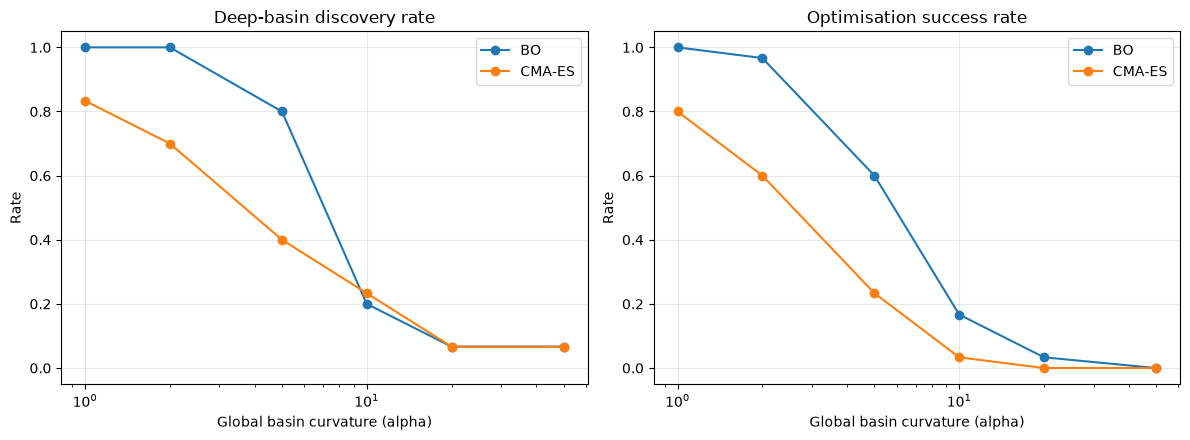

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for method in ["BO", "CMA-ES"]:
    data = summary[summary["method"] == method]

    axes[0].plot(
        data["alpha"],
        data["deep_rate"],
        marker="o",
        label=method
    )

    axes[1].plot(
        data["alpha"],
        data["success_rate"],
        marker="o",
        label=method
    )

axes[0].set_title("Deep-basin discovery rate")
axes[1].set_title("Optimisation success rate")

for ax in axes:
    ax.set_xlabel("Global basin curvature (alpha)")
    ax.set_ylabel("Rate")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xscale("log")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "discovery_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

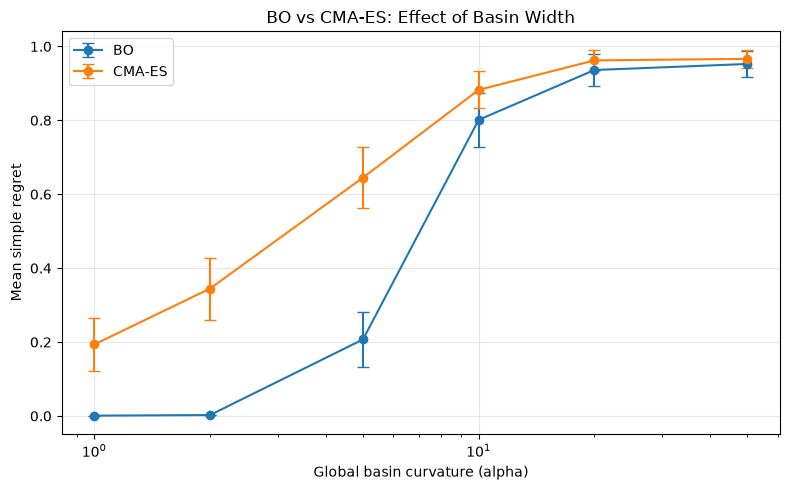

In [36]:
plt.figure(figsize=(8, 5))

for method in ["BO", "CMA-ES"]:
    data = summary[summary["method"] == method]

    plt.errorbar(
        data["alpha"],
        data["mean_regret"],
        yerr=data["std_regret"] / np.sqrt(data["n_runs"]),
        marker="o",
        capsize=4,
        label=method
    )

plt.xscale("log")
plt.xlabel("Global basin curvature (alpha)")
plt.ylabel("Mean simple regret")
plt.title("BO vs CMA-ES: Effect of Basin Width")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "regret_vs_alpha.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()